# **Physics-Informed AI for Environmental Data Science**

**HIDSI Workshop Series · University of Hawaiʻi at Mānoa**  


Materials: https://github.com/FrederikeM9/HIDSI_Physics-Informed_AI

<br>

---

### **Example:** Emulating specific humidity from weather-station data, with and without physics constraints.

We will train the *same* small neural network twice:

1. **Model 1** — learns from data only
2. **Model 2** — learns from data **plus** a physics term in the loss (Clausius–Clapeyron)

and compare how they behave **outside** the conditions they were trained on.

<br>

## **0. Setup check**

Run the cell below. If it prints the package versions without errors, you're ready to go.

- **Google Colab:** everything is pre-installed.
- **Local Jupyter:** if you get a `ModuleNotFoundError`, install the missing packages first, either in a terminal:

  `pip install numpy pandas matplotlib torch`

  or directly in a notebook cell:

  `%pip install numpy pandas matplotlib torch`

  Then restart the kernel (*Kernel → Restart*) and run the cell again.

In [1]:
import io, os, zipfile, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

torch.manual_seed(0)
np.random.seed(0)

# Consistent colors for the whole notebook
C_M1, C_M2, C_TRUE = "#D55E00", "#0072B2", "#333333"   # Model 1, Model 2, truth/physics
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

print("numpy", np.__version__, "| pandas", pd.__version__, "| torch", torch.__version__)

numpy 2.1.3 | pandas 2.2.3 | torch 2.11.0+cpu


## **1. What is our objective?**

**Specific humidity** $q$ (grams of water vapor per kg of moist air) can be *calculated* from temperature $T$, pressure $p$ and relative humidity $RH$ in three steps:

**1. Saturation vapor pressure** — the maximum vapor pressure the air can hold at temperature $T$ (Magnus formula):

$$e_s(T) = 6.112\,\exp\left(\frac{17.62\,T}{243.12 + T}\right) \quad [\text{hPa}]$$

<br>

- $T$ in °C; $6.112$ hPa is $e_s$ at 0 °C; $17.62$ and $243.12$ °C are empirical constants (over liquid water)
- This is an empirical fit to the **Clausius–Clapeyron** equation (more on that in Model 2)

**2. Actual vapor pressure** — relative humidity says how close the air is to saturation:

$$e = \frac{RH}{100}\,e_s \quad [\text{hPa}]$$

**3. Specific humidity:**

$$q = 1000\cdot\frac{0.622\,e}{p - 0.378\,e} \quad [\text{g/kg}]$$

- $p$: air pressure in hPa
- $0.622$: ratio of the molar masses of water vapor and dry air ($\approx 18/29$)
- $0.378 = 1 - 0.622$: small correction because water vapor is part of the total pressure, so $q \approx 622\, e/p$
- $\times 1000$: converts kg/kg to g/kg

<br>

**Task:** Train a neural network to predict $q$ from $(T, p, RH)$ → an **emulator** that skips the calculation.

<br>

Here the calculation is cheap, so we don't *need* an NN. But because we know the true answer, we can measure exactly what physics constraints buy us. In real problems (e.g. radiative transfer) the calculation is expensive or the physics is incomplete. This is where emulators are useful.

## **2. Load & preprocess the data**

**Jena Climate dataset:** weather station of the Max Planck Institute for Biogeochemistry, Jena, Germany (2009–2016, every 10 min, ~420k rows).
The cell uses a local copy if present (e.g. after cloning the repo), otherwise downloads it from a public URL (no account needed), with the workshop's GitHub copy as a backup.

In [2]:
DATA_URLS = [
    "https://storage.googleapis.com/tensorflow/tf-keras-datasets/jena_climate_2009_2016.csv.zip",          # public source
    "https://raw.githubusercontent.com/FrederikeM9/HIDSI_Physics-Informed_AI/main/data/jena_climate_2009_2016.csv.zip",  # backup: workshop repo
]
LOCAL_FILES = ["jena_climate_2009_2016.csv", "data/jena_climate_2009_2016.csv.zip",
               "jena_climate_2009_2016.csv.zip"]

def read_zipped_csv(fileobj):
    zf = zipfile.ZipFile(fileobj)
    name = [n for n in zf.namelist() if n.endswith(".csv") and not n.startswith("__MACOSX")][0]
    return pd.read_csv(zf.open(name))

raw = None
for path in LOCAL_FILES:
    if os.path.exists(path):
        raw = read_zipped_csv(path) if path.endswith(".zip") else pd.read_csv(path)
        print("Loaded local file:", path)
        break
if raw is None:
    for url in DATA_URLS:
        try:
            with urllib.request.urlopen(url, timeout=60) as r:
                raw = read_zipped_csv(io.BytesIO(r.read()))
            print("Downloaded from:", url)
            break
        except Exception as err:
            print("Could not download from", url, "->", err)
assert raw is not None, "Data not found — download the file manually (see README) and place it next to this notebook."

raw.head()

Downloaded from: https://storage.googleapis.com/tensorflow/tf-keras-datasets/jena_climate_2009_2016.csv.zip


,Date Time,p (mbar),T (degC),Tpot (K),Tdew (degC),rh (%),VPmax (mbar),VPact (mbar),VPdef (mbar),sh (g/kg),H2OC (mmol/mol),rho (g/m**3),wv (m/s),max. wv (m/s),wd (deg)
0,01.01.2009 00:10:00,996.52,-8.02,265.40,-8.90,93.3,3.33,3.11,0.22,1.94,3.12,1307.75,1.03,1.75,152.3
1,01.01.2009 00:20:00,996.57,-8.41,265.01,-9.28,93.4,3.23,3.02,0.21,1.89,3.03,1309.80,0.72,1.50,136.1
2,01.01.2009 00:30:00,996.53,-8.51,264.91,-9.31,93.9,3.21,3.01,0.20,1.88,3.02,1310.24,0.19,0.63,171.6
3,01.01.2009 00:40:00,996.51,-8.31,265.12,-9.07,94.2,3.26,3.07,0.19,1.92,3.08,1309.19,0.34,0.50,198.0
4,01.01.2009 00:50:00,996.51,-8.27,265.15,-9.04,94.1,3.27,3.08,0.19,1.92,3.09,1309.00,0.32,0.63,214.3


In [3]:
# Only keep variables we need, rename to short names, use hourly values (every 6th row)
df = raw[["Date Time", "T (degC)", "p (mbar)", "rh (%)", "sh (g/kg)"]].copy()
df.columns = ["time", "T", "p", "rh", "q"]
df["time"] = pd.to_datetime(df["time"], format="%d.%m.%Y %H:%M:%S")
df = df.iloc[5::6].dropna().reset_index(drop=True)

print(f"{len(df):,} hourly samples")
df.describe().round(2)

70,091 hourly samples


,time,T,p,rh,q
count,70091,70091.00,70091.00,70091.00,70091.00
mean,2012-12-30 06:26:49.413476608,9.45,989.21,76.01,6.02
min,2009-01-01 01:00:00,-22.76,913.60,13.88,0.51
25%,2010-12-31 03:50:00,3.35,984.20,65.21,3.92
50%,2012-12-30 06:20:00,9.41,989.57,79.30,5.59
75%,2014-12-29 18:30:00,15.48,994.72,89.40,7.80
max,2016-12-31 23:10:00,37.28,1015.29,100.00,18.07
std,NaN,8.42,8.36,16.47,2.66


<details><summary>What we see:</summary>

70,091 hourly samples from 2009–2016.
- **Temperature:** −22.8 to 37.3 °C (−9 to 99 °F), mean 9.5 °C (49 °F)
- **Pressure:** 914 to 1015 hPa, typically ~990 hPa
- **Relative humidity:** 14 to 100 %
- **Specific humidity:** 0.5 to 18.1 g/kg, mean 6.0 g/kg

For reference: our training cutoff of 20 °C = 68 °F, and the collocation range −20 to 35 °C = −4 to 95 °F.

## **3. Input & output**

| | variables | units |
|---|---|---|
| **Input** $x$ | temperature $T$, pressure $p$, relative humidity $RH$ | °C, hPa, % |
| **Output** $y$ | specific humidity $q$ | g/kg |

<br>

**Quick sanity check:** Does the formula above reproduce the measured $q$?

RMSE measured vs. calculated q: 0.023 g/kg


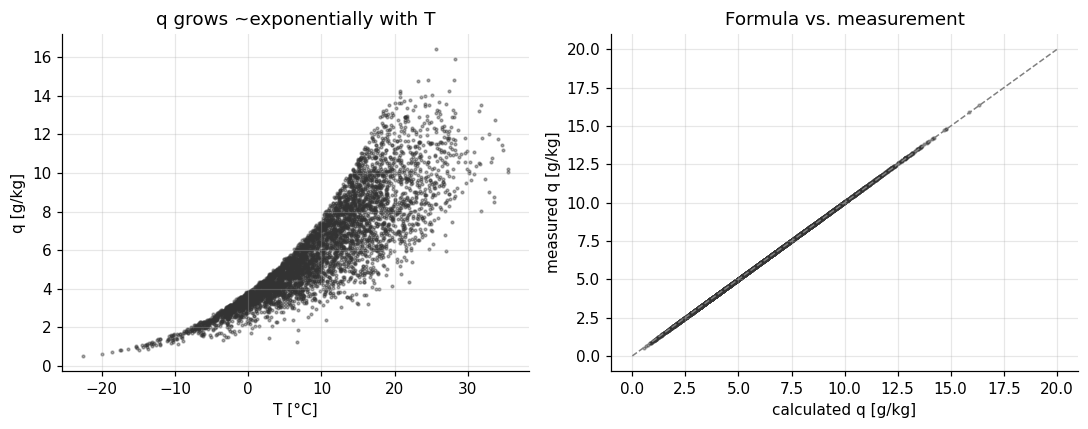

In [4]:
def q_physics(T, p, rh):
    # Specific humidity [g/kg] from T [degC], p [hPa], rh [%] (Magnus formula)
    es = 6.112 * np.exp(17.62 * T / (243.12 + T))
    e = rh / 100 * es
    return 1000 * 0.622 * e / (p - 0.378 * e)

q_calc = q_physics(df["T"], df["p"], df["rh"])
print(f"RMSE measured vs. calculated q: {np.sqrt(np.mean((df['q'] - q_calc)**2)):.3f} g/kg")

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
s = df.sample(5000, random_state=0)
ax[0].scatter(s["T"], s["q"], s=3, alpha=0.4, color=C_TRUE)
ax[0].set(xlabel="T [°C]", ylabel="q [g/kg]", title="q grows ~exponentially with T")
ax[1].scatter(q_physics(s["T"], s["p"], s["rh"]), s["q"], s=3, alpha=0.4, color=C_TRUE)
ax[1].plot([0, 20], [0, 20], "--", color="gray", lw=1)
ax[1].set(xlabel="calculated q [g/kg]", ylabel="measured q [g/kg]", title="Formula vs. measurement")
plt.tight_layout(); plt.show()

<details><summary>What we see:</summary>

- **RMSE** (root-mean-square error) is the typical difference between two sets of values, in their units (here g/kg): square the differences, average them, take the square root. Here it's only **0.023 g/kg** (≈ 0.4 % of the mean $q$), so the formula and the measurements agree very well.
- **Left:** $q$ grows faster and faster with $T$. The vertical spread comes from different relative humidities: at the same temperature, humid air contains much more water than dry air.
- **Right:** calculated vs. measured $q$. All points lie on the dashed 1:1 line → the formula reproduces the measurements.

### **Train/test split — testing *extrapolation***

A random split would only test the model on conditions it has already seen.
Instead we **train on cooler conditions** and keep the **warm conditions as a separate test set**:

- **train** — $T < 20$ °C (80 %)
- **test (cold)** — $T < 20$ °C (20 %, held out) → *interpolation*
- **test (warm)** — $T \geq 20$ °C, never seen in training → *extrapolation*

In [5]:
T_CUTOFF = 20.0   # °C — try changing this later!

cold = df[df["T"] < T_CUTOFF].sample(frac=1, random_state=0)
warm = df[df["T"] >= T_CUTOFF]
n_train = int(0.8 * len(cold))
train, test_cold = cold.iloc[:n_train], cold.iloc[n_train:]

def to_tensors(d):
    x = torch.tensor(d[["T", "p", "rh"]].values, dtype=torch.float32)
    y = torch.tensor(d[["q"]].values, dtype=torch.float32)
    return x, y

x_train, y_train = to_tensors(train)
x_cold,  y_cold  = to_tensors(test_cold)
x_warm,  y_warm  = to_tensors(warm)
print(f"train: {len(train):,} | test cold: {len(test_cold):,} | test warm: {len(warm):,}")

train: 50,086 | test cold: 12,522 | test warm: 7,483


## **4. Reminder: a simple neural network**

Same network as on the slides. Each layer computes

$$h = \sigma(W x + b)$$

- $x$: inputs, $h$: output of the layer (passed on to the next layer)
- $W, b$: weights and biases, learned from data
- $\sigma$: nonlinear activation function (here `tanh`)
  - `tanh` squashes any number into the range −1 to 1: roughly linear near 0, and it flattens out for large positive or negative values
  - without an activation function, stacking layers would still only give a straight-line (linear) relationship
- The whole network: $q_{\text{NN}} = f(x)$ → the network's prediction of $q$ (on slides: $\hat{q}$ = $q_{\text{NN}}$)

<br>

Our network: **3 inputs ($T, p, RH$) → 2 hidden layers × 32 neurons → 1 output ($q_{\text{NN}}$)**. Inputs are standardized inside the model (each input is shifted and scaled to mean 0, standard deviation 1), which makes training easier.

In [6]:
class MLP(nn.Module):
    """Small fully connected neural network (multi-layer perceptron): (T, p, RH) -> q."""
    def __init__(self, x_ref, y_ref, hidden=32, n_layers=2):
        super().__init__()
        layers, d = [], 3                                 # d = number of inputs to the next layer (3: T, p, RH)
        for _ in range(n_layers):
            layers += [nn.Linear(d, hidden), nn.Tanh()]   # one hidden layer: W x + b, then tanh
            d = hidden                                    # the next layer gets `hidden` inputs
        layers.append(nn.Linear(d, 1))                    # output layer: a single value (q), no activation
        self.net = nn.Sequential(*layers)                 # chain the layers: inputs -> hidden -> hidden -> output
        # Standardization constants: mean and standard deviation of the training data
        # (stored inside the model as fixed values, they are not trained)
        self.register_buffer("x_mean", x_ref.mean(0)); self.register_buffer("x_std", x_ref.std(0))
        self.register_buffer("y_mean", y_ref.mean(0)); self.register_buffer("y_std", y_ref.std(0))

    def forward(self, x):                                 # x in physical units (°C, hPa, %) -> q in g/kg
        z = (x - self.x_mean) / self.x_std                # standardize: each input gets mean 0, std 1
        return self.net(z) * self.y_std + self.y_mean     # run the network, scale the output back to g/kg

## **5. Model 1 — plain NN (data only)**

Loss = mean squared error between predictions $q_{\text{NN}}$ and observations $q$ on the $N$ training samples:

$$L_{\text{data}} = \frac{1}{N}\sum_{i=1}^{N} \left(q_{\text{NN},i} - q_i\right)^2$$

<br>

Training loop: forward pass → loss → backpropagation → weight update, repeated for `EPOCHS` passes through the data (in mini-batches of `BATCH` samples).

<br>

> 🔧 **Try it yourself:** while others catch up, change `HIDDEN`, `N_LAYERS`, `EPOCHS` or `LR` (learning rate) and re-run this cell.

In [7]:
HIDDEN, N_LAYERS = 32, 2          # neurons per hidden layer, number of hidden layers
EPOCHS, LR, BATCH = 30, 1e-3, 512 # passes through the data, learning rate, samples per mini-batch

def train_model(model, lambda_phys=0.0, epochs=EPOCHS, lr=LR, verbose=True, loss_fn=None):
    # lambda_phys: weight of the physics term (0 = data only)
    # loss_fn: which physics loss to use (defaults to physics_loss, defined in Model 2)
    opt = torch.optim.Adam(model.parameters(), lr=lr)     # Adam: an improved version of gradient descent
    n = len(x_train)
    for ep in range(epochs):                               # one epoch = one pass through all training data
        perm = torch.randperm(n)                           # shuffle the training data
        for i in range(0, n, BATCH):                       # go through the data in mini-batches
            idx = perm[i:i + BATCH]
            # 1) forward pass + data loss: mean squared error between prediction and observation
            loss_data = ((model(x_train[idx]) - y_train[idx])**2).mean()
            # physics loss (only if lambda_phys > 0, i.e. for Model 2 and the constraint ladder)
            loss_phys = (loss_fn or physics_loss)(model) if lambda_phys > 0 else torch.tensor(0.0)
            # 2) total loss: L = L_data + lambda * L_physics
            loss = loss_data + lambda_phys * loss_phys
            opt.zero_grad()                                # reset the gradients from the previous step
            loss.backward()                                # 3) backpropagation: gradients of the loss w.r.t. all weights
            opt.step()                                     # 4) weight update: small step downhill
        if verbose and (ep % 10 == 9 or ep == 0):          # print the losses after epoch 1, 10, 20, 30
            print(f"epoch {ep+1:3d} | data loss {loss_data.item():.4f} | physics loss {loss_phys.item():.4f}")
    return model

# Train Model 1: data only (lambda_phys = 0)
model1 = train_model(MLP(x_train, y_train, HIDDEN, N_LAYERS), lambda_phys=0.0)

epoch   1 | data loss 0.1634 | physics loss 0.0000
epoch  10 | data loss 0.0070 | physics loss 0.0000
epoch  20 | data loss 0.0006 | physics loss 0.0000
epoch  30 | data loss 0.0002 | physics loss 0.0000


## **6. Model 2 — same NN + physics constraint**

### **The physics: Clausius–Clapeyron**

The **Clausius–Clapeyron equation** describes how fast the saturation vapor pressure grows with temperature:

$$\frac{d\,\ln e_s}{dT} = \frac{L_v}{R_v\,T_K^2}$$

- $L_v \approx 2.5\times10^6$ J/kg: latent heat of vaporization
- $R_v = 461.5$ J/(kg K): gas constant of water vapor
- $T_K$: temperature in **kelvin**

<br>

At 15 °C this gives $2.5\times10^6 / (461.5 \cdot 288^2) \approx 0.065$, i.e. **about 6.5 % more water vapor per kelvin** of warming.

**From $e_s$ to $q$:** at fixed $RH$ and $p$, $q \approx 622 \cdot \frac{RH}{100} \cdot \frac{e_s(T)}{p}$ is proportional to $e_s$, so $q$ grows at the same relative rate:

$$\frac{\partial q}{\partial T} \approx \frac{L_v}{R_v\,T_K^2}\; q$$

(This is approximate: $L_v$ is held constant and the small $0.378\,e$ term is neglected.)

<br>

### **The physics loss**

We turn this into an extra loss term. The **physics residual** is how much the network's prediction $q_{\text{NN}}$ violates the equation, it should be close to zero:

$$r = \frac{\partial q_{\text{NN}}}{\partial T} - \frac{L_v}{R_v\,T_K^2}\,q_{\text{NN}}$$

The total loss adds the mean squared residual over $M$ collocation points, weighted by $\lambda$:

$$L = L_{\text{data}} + \lambda\,L_{\text{physics}}, \qquad L_{\text{physics}} = \frac{1}{M}\sum_{j=1}^{M} r_j^2$$

**Two key ideas:**
- $\partial q_{\text{NN}} / \partial T$ of the *network* is computed with **automatic differentiation** (`torch.autograd.grad`).
- The physics term needs **no labels**, so we can evaluate it on **"collocation points"** sampled anywhere in a plausible input range, including warmer conditions we have no training data for.

<br>

**Note:** the physics term only tells the network **how fast $q$ should grow with $T$** (the slope), not the full formula — no Magnus constants, no dependence on $p$ or $RH$, no absolute values. Those still have to be learned from the data: the physics fixes the *slope* of the curve, the data pins down *where the curve sits*.

In [8]:
L_V, R_V = 2.5e6, 461.5  # latent heat of vaporization [J/kg], gas constant of water vapor [J/(kg K)]
LAMBDA_PHYS = 10.0       # weight of the physics term — try 0.1, 10, 100
N_COLLOC = 512           # collocation points per training step

def sample_collocation(n):
    # Collocation points: random made-up inputs (T, p, RH) where we check the physics.
    # No measured q needed! The T range goes up to 35 °C, beyond the training data (< 20 °C).
    T  = torch.empty(n, 1).uniform_(-20, 35)                         # temperature [°C]
    p  = torch.empty(n, 1).uniform_(df["p"].min(), df["p"].max())    # pressure [hPa], observed range
    rh = torch.empty(n, 1).uniform_(5, 100)                          # relative humidity [%]
    return torch.cat([T, p, rh], dim=1)                              # shape (n, 3), same as the training inputs

def physics_loss(model):
    x = sample_collocation(N_COLLOC).requires_grad_(True)   # track gradients with respect to the inputs
    q = model(x)                                             # network prediction q_NN at the collocation points
    # Automatic differentiation: dq/dT, dq/dp, dq/dRH at every point
    # (create_graph=True: the derivative itself must be differentiable for backpropagation)
    dq_dx = torch.autograd.grad(q.sum(), x, create_graph=True)[0]
    dq_dT = dq_dx[:, :1]                                     # first column: derivative with respect to T
    T_K = x[:, :1] + 273.15                                  # Clausius–Clapeyron needs T in kelvin
    residual = dq_dT - L_V / (R_V * T_K**2) * q              # r = dq/dT − L_v/(R_v T²)·q, should be ≈ 0
    return (residual**2).mean()                              # L_physics = mean squared residual

# Train Model 2: same network and data, now with the physics term
torch.manual_seed(0)
model2 = train_model(MLP(x_train, y_train, HIDDEN, N_LAYERS), lambda_phys=LAMBDA_PHYS)

epoch   1 | data loss 0.1866 | physics loss 0.0323
epoch  10 | data loss 0.0115 | physics loss 0.0140
epoch  20 | data loss 0.0030 | physics loss 0.0021
epoch  30 | data loss 0.0009 | physics loss 0.0010


## **7. Evaluate & compare**

In [9]:
def rmse(model, x, y):
    # root-mean-square error: typical size of the prediction error [g/kg]
    with torch.no_grad():
        return torch.sqrt(((model(x) - y)**2).mean()).item()

results = pd.DataFrame({
    "Model 1 (data only)": [rmse(model1, x_cold, y_cold), rmse(model1, x_warm, y_warm)],
    "Model 2 (physics)":   [rmse(model2, x_cold, y_cold), rmse(model2, x_warm, y_warm)],
}, index=["test cold (interpolation)", "test warm (extrapolation)"])
results.round(3).rename_axis("RMSE [g/kg]")

,Model 1 (data only),Model 2 (physics)
RMSE [g/kg],,
test cold (interpolation),0.014,0.037
test warm (extrapolation),0.280,0.136


<details><summary>What we see (your numbers may differ slightly):</summary>


| RMSE [g/kg] | test cold (interpolation) | test warm (extrapolation) |
|---|---|---|
| Model 1 (data only) | 0.014 | 0.280 |
| Model 2 (physics) | 0.037 | 0.136 |

- **Cold test:** both models are very accurate; Model 1 is even slightly better (more on why in the discussion).
- **Warm test:** Model 1's error is **~20× larger** than on the cold test. Model 2 **cuts the warm-range error roughly in half**.

## **8. Visualizations**

### **(a) Predicted vs. observed**

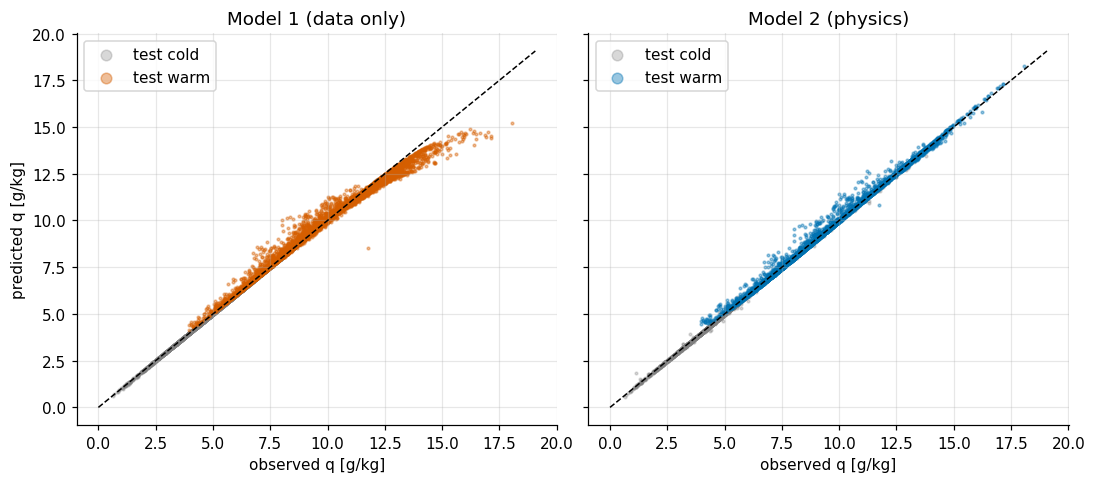

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5), sharex=True, sharey=True)
with torch.no_grad():
    for ax, model, name, c in zip(axes, [model1, model2], ["Model 1 (data only)", "Model 2 (physics)"], [C_M1, C_M2]):
        ax.scatter(y_cold[:3000], model(x_cold[:3000]), s=3, alpha=0.3, color="gray", label="test cold")
        ax.scatter(y_warm, model(x_warm), s=3, alpha=0.4, color=c, label="test warm")
        lim = [0, float(y_warm.max()) + 1]
        ax.plot(lim, lim, "--", color="black", lw=1)
        ax.set(title=name, xlabel="observed q [g/kg]")
        ax.legend(markerscale=4, loc="upper left")
axes[0].set_ylabel("predicted q [g/kg]")
plt.tight_layout(); plt.show()

<details><summary>What we see:</summary>

Each dot is one test sample; the dashed line marks perfect predictions. Grey = cold test, colored = warm test.
- Both models are right on the line for the **cold** test.
- **Model 1** scatters away from the line for the **warm** test: too high around 6–11 g/kg, and too low for the most humid cases (above ~12 g/kg), where its predictions level off around 15 g/kg.
- **Model 2** stays much closer to the line, also for the most humid cases.

### **(b) What did each model learn? — response to temperature**
$q$ depends on three inputs, but a line plot can only show one. So we **keep pressure and relative humidity fixed** at typical values ($p$ = 990 hPa, $RH$ = 70 %) and **vary only temperature** from −20 to 35 °C. Then we compare both models with the exact formula.

<br>

> 🔧 **Try it yourself:** change `P_FIX` or `RH_FIX` in the cell below and re-run it. The curves shift, but does the overall pattern change?

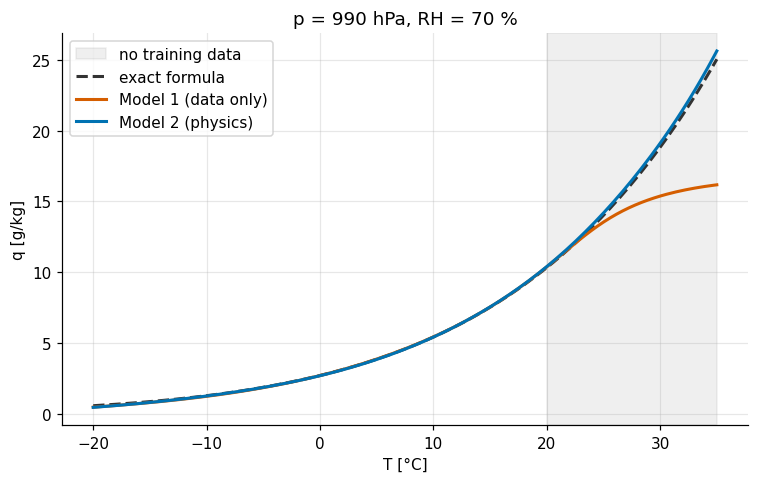

In [11]:
P_FIX, RH_FIX = 990.0, 70.0
T_sweep = np.linspace(-20, 35, 200)
x_sweep = torch.tensor(np.column_stack([T_sweep, np.full_like(T_sweep, P_FIX), np.full_like(T_sweep, RH_FIX)]),
                       dtype=torch.float32)

with torch.no_grad():
    q1, q2 = model1(x_sweep).squeeze().numpy(), model2(x_sweep).squeeze().numpy()

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.axvspan(T_CUTOFF, T_sweep.max(), color="gray", alpha=0.12, label="no training data")
ax.plot(T_sweep, q_physics(T_sweep, P_FIX, RH_FIX), color=C_TRUE, lw=2, ls="--", label="exact formula")
ax.plot(T_sweep, q1, color=C_M1, lw=2, label="Model 1 (data only)")
ax.plot(T_sweep, q2, color=C_M2, lw=2, label="Model 2 (physics)")
ax.set(xlabel="T [°C]", ylabel="q [g/kg]", title=f"p = {P_FIX:.0f} hPa, RH = {RH_FIX:.0f} %")
ax.legend(loc="upper left"); plt.tight_layout(); plt.show()

<details><summary>What we see:</summary>

The grey area marks temperatures with no training data.
- Below 20 °C, all three curves lie on top of each other: both models learned the data well.
- Above 20 °C, **Model 1 flattens out**: at 35 °C it predicts ~16 g/kg instead of ~25 g/kg. Remember that `tanh` flattens out for large inputs: outside the training data, the network just continues smoothly and levels off, while the true curve keeps getting steeper.
- **Model 2 keeps bending upward** and follows the exact formula closely. It never saw a warm sample, but the physics term told it how steep the curve has to be.

### **(c) Error as a function of temperature**

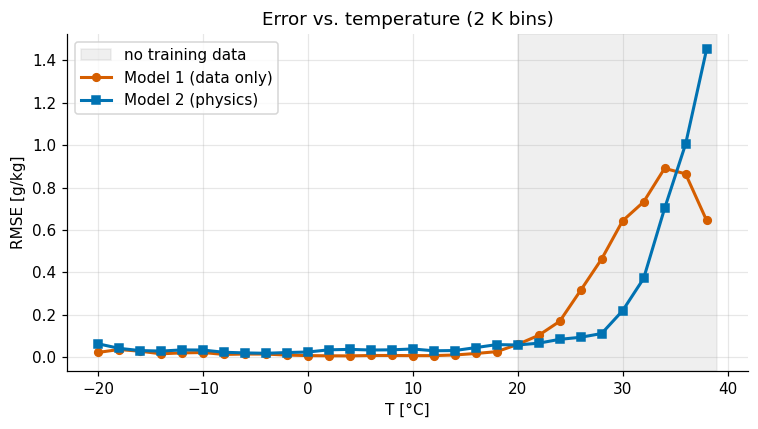

In [12]:
test_all = pd.concat([test_cold, warm])
x_all, y_all = to_tensors(test_all)
with torch.no_grad():
    test_all = test_all.assign(err1=(model1(x_all) - y_all).squeeze().numpy(),
                               err2=(model2(x_all) - y_all).squeeze().numpy())
bins = np.arange(np.floor(test_all["T"].min()), test_all["T"].max() + 2, 2)
g = test_all.groupby(pd.cut(test_all["T"], bins), observed=True)
centers = [iv.mid for iv in g.groups.keys()]
rmse1 = g["err1"].apply(lambda e: np.sqrt((e**2).mean())).values
rmse2 = g["err2"].apply(lambda e: np.sqrt((e**2).mean())).values

fig, ax = plt.subplots(figsize=(7, 4))
ax.axvspan(T_CUTOFF, bins.max(), color="gray", alpha=0.12, label="no training data")
ax.plot(centers, rmse1, "o-", color=C_M1, lw=2, ms=5, label="Model 1 (data only)")
ax.plot(centers, rmse2, "s-", color=C_M2, lw=2, ms=5, label="Model 2 (physics)")
ax.set(xlabel="T [°C]", ylabel="RMSE [g/kg]", title="Error vs. temperature (2 K bins)")
ax.legend(loc="upper left"); plt.tight_layout(); plt.show()

<details><summary>What we see:</summary>

The error (RMSE) in 2 K temperature bins.
- Below 20 °C, both errors are small and flat.
- From 20 to ~32 °C, **Model 1's error grows quickly**, while Model 2's stays low. This is where most of the warm test samples are.
- At the **very hottest temperatures** (above ~34 °C), Model 2's error also grows, and in the last bins it is even larger than Model 1's. There are only a few hours that hot, and above 35 °C there are no collocation points, so no physics guidance. Also, the physics only fixes the *relative* growth rate: a small offset gets amplified as $q$ grows exponentially.

## **9. Constraint ladder — does *more* physics always help?**

Same network, same data, different physics terms → from weak to strong knowledge about how $q$ depends on $T$:

| Variant | Physics in the loss | In words | What it tells the model |
|---|---|---|---|
| A | $q \geq 0$ and $\dfrac{\partial q}{\partial T} \geq 0$ | humidity can't be negative; warmer air holds more water (at fixed $RH$) | the **direction** ("go uphill") |
| B | A + $\dfrac{\partial^2 q}{\partial T^2} \geq 0$ | $q$ increases faster and faster with $T$ (curve bends upward, like an exponential) | the **shape** ("get steeper") |
| C | Clausius–Clapeyron | $q$ grows by ~6–7 % per K | the **exact rate** ("exactly this steep") |

<br>

**How the penalties work:** A and B are *inequality* constraints. They use `relu(-x)`, which is zero when $x \geq 0$ and only penalizes **violations** (e.g., a negative slope).
(`relu(x)` = max(0, x), the *rectified linear unit*: it returns $x$ if $x$ is positive and 0 otherwise. It's also a popular activation function, but for physics losses we use `tanh`, because it is smooth and has useful second derivatives.) If the model already satisfies them, they add nothing. C is an *equality* constraint: any deviation from the Clausius–Clapeyron rate is penalized. (The convexity term is multiplied by 100 because second derivatives are small numbers.)

**Before running:** which variant do you expect to fix the warm-range extrapolation?

In [13]:
relu = torch.nn.functional.relu        # relu(x) = max(0, x)

def derivatives_T(model):
    # q, dq/dT and d2q/dT2 of the network at random collocation points
    x = sample_collocation(N_COLLOC).requires_grad_(True)
    q = model(x)
    dq_dT = torch.autograd.grad(q.sum(), x, create_graph=True)[0][:, :1]
    # differentiate dq/dT once more -> second derivative (curvature)
    d2q_dT2 = torch.autograd.grad(dq_dT.sum(), x, create_graph=True)[0][:, :1]
    return q, dq_dT, d2q_dT2

def loss_A(model):   # positivity + monotonicity
    # relu(-q) > 0 only if q < 0; relu(-dq) > 0 only if q decreases with T
    q, dq, _ = derivatives_T(model)
    return (relu(-q)**2).mean() + (relu(-dq)**2).mean()

def loss_B(model):   # A + convexity (x100: curvature values are small)
    # relu(-d2q) > 0 only if the curve bends downward
    q, dq, d2q = derivatives_T(model)
    return (relu(-q)**2).mean() + (relu(-dq)**2).mean() + 100 * (relu(-d2q)**2).mean()

# Train variants A and B with the same settings; Model 1 and Model 2 (= C) are reused
models = {"Model 1 (data only)": model1}
for name, fn in [("A: positive + monotonic", loss_A), ("B: + convex", loss_B)]:
    torch.manual_seed(0)
    print("training", name, "...")
    models[name] = train_model(MLP(x_train, y_train, HIDDEN, N_LAYERS), lambda_phys=LAMBDA_PHYS,
                               loss_fn=fn, verbose=False)
models["C: Clausius-Clapeyron (Model 2)"] = model2

ladder = pd.DataFrame({name: [rmse(m, x_cold, y_cold), rmse(m, x_warm, y_warm)] for name, m in models.items()},
                      index=["test cold (interpolation)", "test warm (extrapolation)"]).T
ladder.round(3).rename_axis("RMSE [g/kg]")

training A: positive + monotonic ...
training B: + convex ...


,test cold (interpolation),test warm (extrapolation)
RMSE [g/kg],,
Model 1 (data only),0.014,0.280
A: positive + monotonic,0.013,0.315
B: + convex,0.042,0.389
C: Clausius-Clapeyron (Model 2),0.037,0.136


<details><summary>What we see (your numbers may differ slightly):</summary>

| RMSE [g/kg] | test cold | test warm |
|---|---|---|
| Model 1 (data only) | 0.014 | 0.280 |
| A: positive + monotonic | 0.013 | 0.315 |
| B: + convex | 0.042 | 0.389 |
| C: Clausius–Clapeyron (Model 2) | 0.037 | **0.136** |

- **A** changes basically nothing; it's about the same as Model 1.
- **B** is even worse, on both test sets.
- Only **C** clearly improves the warm range.

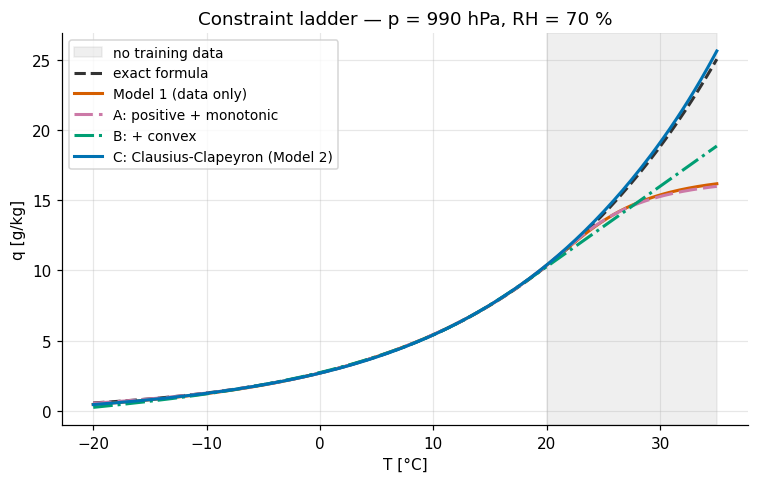

In [14]:
styles = {"Model 1 (data only)":             (C_M1,      "-"),
          "A: positive + monotonic":         ("#CC79A7", (0, (6, 2))),
          "B: + convex":                     ("#009E73", "-."),
          "C: Clausius-Clapeyron (Model 2)": (C_M2,      "-")}

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.axvspan(T_CUTOFF, T_sweep.max(), color="gray", alpha=0.12, label="no training data")
ax.plot(T_sweep, q_physics(T_sweep, P_FIX, RH_FIX), color=C_TRUE, lw=2, ls="--", label="exact formula")
with torch.no_grad():
    for name, m in models.items():
        c, ls = styles[name]
        ax.plot(T_sweep, m(x_sweep).squeeze().numpy(), color=c, ls=ls, lw=2, label=name)
ax.set(xlabel="T [°C]", ylabel="q [g/kg]", title=f"Constraint ladder — p = {P_FIX:.0f} hPa, RH = {RH_FIX:.0f} %")
ax.legend(loc="upper left", fontsize=9); plt.tight_layout(); plt.show()

<details><summary>What we see:</summary>

Same setup as in plot (b): fixed $p$ = 990 hPa and $RH$ = 70 %, only $T$ varies.
- **A** lies right on top of Model 1: both flatten out above 20 °C.
- **B** bends upward a bit more at the hot end, but still far too slowly, and between 20 and 28 °C it is slightly *below* the exact curve, where most warm samples are.
- Only **C** follows the exact formula.

### **Takeaway:**
It's not *how much* physics you add, but whether it constrains what the model gets wrong.
Model 1 never goes negative or decreases — it just grows too slowly — so positivity and monotonicity (A) are already satisfied and change nothing.
Knowing only the *shape* (B) isn't enough either: it bends the curve upward a bit more, but without the right rate it still grows too slowly, and it fits the 20–28 °C range (where most warm samples are) worse, so the error even increases.
Only the correct *growth rate* (C) fixes the extrapolation. (And stronger constraints only help as long as the physics is correct!)


<br>

## **10. Discussion**

1. **Why does the physics term help in the warm range, even though we had no data there?**
<details><summary>Answer</summary>

The physics loss needs no labels. We checked it at collocation points up to 35 °C, so the network was told how fast $q$ must grow even where we had no observations. The data pin down the curve in the cold range; the physics tells the network how to continue it.
</details>

2. **Why is Model 2 slightly worse on the cold test?** *Hint: how exact is our physics?*
<details><summary>Answer</summary>

Our Clausius–Clapeyron constraint is approximate: $L_v$ is held constant, the small $0.378\,e$ term is neglected, and the data follow the Magnus formula, not exactly our equation. Data and physics disagree slightly, so the model compromises. Where data are plentiful, that costs a little accuracy. That trade-off is what $\lambda$ controls.
</details>

3. **Why didn't constraints A and B help?** *Hint: what did Model 1 actually get wrong?*
<details><summary>Answer</summary>

Model 1 never went negative or downhill; it only grew too slowly. A constraint that is already satisfied adds nothing (A). B adds a competing goal that makes training harder without fixing the growth rate. Constraints have to target the model's actual errors.
</details>

4. **Where might constraints not help, or even hurt?** *What if the physics were wrong or incomplete?*
<details><summary>Answer</summary>

Wrong physics pulls the model in the wrong direction and can be worse than no physics. Constraints also don't help when there are plenty of data everywhere, or when they don't target the model's errors. And PINNs can be hard to train (choosing $\lambda$, competing losses).
</details>

5. **Your research:** which physical laws could constrain a model in your field?
<details><summary>Some ideas</summary>

Conservation of mass, energy or water · non-negativity (rainfall, concentrations) · known bounds (e.g., $0 \leq RH \leq 100$ %) · symmetries · balance equations (hydrostatic, geostrophic)
</details>

<br>



### 🔧 Try it yourself
- Change `LAMBDA_PHYS` (0.1, 10, 100) and re-run Model 2. What happens at the extremes?
- Change `T_CUTOFF` to 15 or 25 °C.
- Restrict the collocation range to the training range (`uniform_(-20, T_CUTOFF)`). Does Model 2 still extrapolate?